[![preview notebook](https://img.shields.io/static/v1?label=render%20on&logo=github&color=87ce3e&message=GitHub)](https://github.com/open-atmos/PySDM/blob/main/examples/PySDM_examples/sandbox/Abade_and_Albuquerque_2024/sampling_explanation.ipynb)
[![launch on mybinder.org](https://mybinder.org/badge_logo.svg)](https://mybinder.org/v2/gh/open-atmos/PySDM.git/main?urlpath=lab/tree/examples/PySDM_examples/sandbox/Abade_and_Albuquerque_2024/sampling_explanation.ipynb)
[![launch on Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/open-atmos/PySDM/blob/main/examples/PySDM_examples/sandbox/Abade_and_Albuquerque_2024/sampling_explanation.ipynb)

This notebook illustrates how particle attributes are sampled in the singular and time-dependent immersion freezing models and compares the resulting distributions.

In [1]:
import os, sys
os.environ['NUMBA_THREADING_LAYER'] = 'workqueue'  # PySDM & PyMPDATA don't work with TBB; OpenMP has extra dependencies on macOS
if 'google.colab' in sys.modules:
    !pip --quiet install open-atmos-jupyter-utils
    from open_atmos_jupyter_utils import pip_install_on_colab
    pip_install_on_colab('PySDM-examples', 'PySDM')

In [2]:
import numpy as np
from PySDM_examples.sandbox.Abade_and_Albuquerque_2024.sampling import sampling, sampling_new
from PySDM import Formulae
from PySDM.physics import si
from PySDM_examples.featured.Arabas_et_al_2025.commons import FREEZING_CONSTANTS
from matplotlib import pyplot as plt
from PySDM.initialisation.spectra import Lognormal

In [3]:
attributessing_old={}
attributestdep_old={}
formulae=Formulae(
    constants={
            **FREEZING_CONSTANTS["dust"],
        },
    freezing_temperature_spectrum="Niemand_et_al_2012",
)
rng=np.random.default_rng(seed=444)

sampling(n_sd=1000, freezing_inp_frac=0.5,rng=rng,attributes=attributessing_old, formulae=formulae, singular=True, freezing_inp_dry_radius=10.0*si.um)
sampling(n_sd=1000, freezing_inp_frac=0.5,rng=rng,attributes=attributestdep_old, formulae=formulae, singular=False, freezing_inp_dry_radius=10.0*si.um)

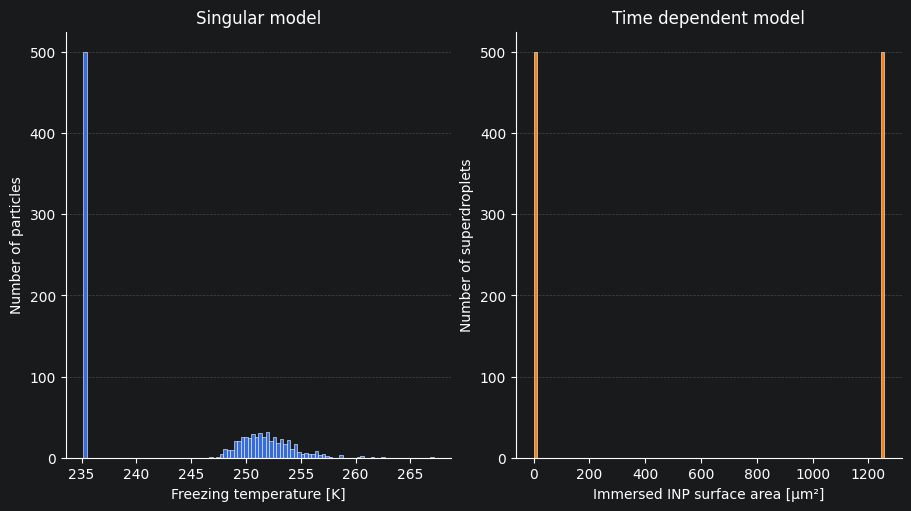

In [4]:
fig, ax = plt.subplots(1,2, figsize = (9,5), constrained_layout=True,)
ax[0].hist(attributessing_old["freezing temperature"], bins=100, linewidth=0.4, edgecolor="white")
ax[0].set(xlabel="Freezing temperature [K]", ylabel="Number of particles")
ax[0].grid(axis="y", linestyle="--", alpha=0.3)
ax[0].set_axisbelow(True)
ax[0].spines[["top", "right"]].set_visible(False)
ax[0].set(title="Singular model")

ax[1].hist(
    attributestdep_old["immersed surface area"] / si.um**2, bins=100, linewidth=0.4, edgecolor="white", color="tab:orange",
)
ax[1].set(xlabel="Immersed INP surface area [µm²]", ylabel="Number of superdroplets")
ax[1].grid(axis="y", linestyle="--", alpha=0.3)
ax[1].set_axisbelow(True)
ax[1].spines[["top", "right"]].set_visible(False)
ax[1].set(title="Time dependent model")
plt.show()

In [5]:
attributessing_new={}
attributestdep_new={}

sampling_new(n_sd=1000, freezing_inp_frac=0.5,rng=rng,attributes=attributessing_new, formulae=formulae, singular=True, freezing_inp_dry_radius=10.0*si.um, inp_surface_sigma=2.5)
sampling_new(n_sd=1000, freezing_inp_frac=0.5,rng=rng,attributes=attributestdep_new, formulae=formulae, singular=False, freezing_inp_dry_radius=10.0*si.um, inp_surface_sigma=2.5)

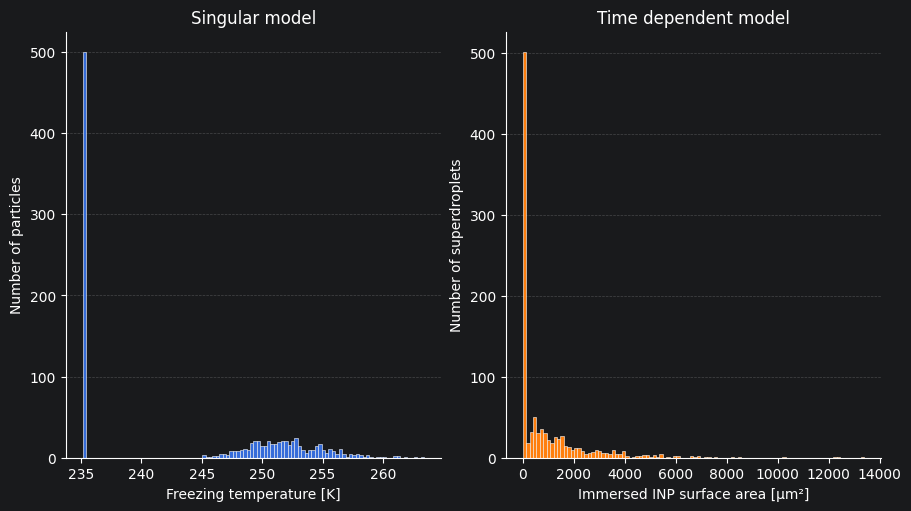

In [6]:
fig, ax = plt.subplots(1,2, figsize = (9,5), constrained_layout=True,)
ax[0].hist(attributessing_new["freezing temperature"], bins=100, linewidth=0.4, edgecolor="white")
ax[0].set(xlabel="Freezing temperature [K]", ylabel="Number of particles")
ax[0].grid(axis="y", linestyle="--", alpha=0.3)
ax[0].set_axisbelow(True)
ax[0].spines[["top", "right"]].set_visible(False)
ax[0].set(title="Singular model")

ax[1].hist(
    attributestdep_new["immersed surface area"] / si.um**2, bins=100, linewidth=0.4, edgecolor="white", color="tab:orange",
)
ax[1].set(xlabel="Immersed INP surface area [µm²]", ylabel="Number of superdroplets")
ax[1].grid(axis="y", linestyle="--", alpha=0.3)
ax[1].set_axisbelow(True)
ax[1].spines[["top", "right"]].set_visible(False)
ax[1].set(title="Time dependent model")
plt.show()

In [7]:
temperature = np.linspace(230, 273.15, 300) * si.K
area = np.geomspace(1, 1e5, 300) * si.um**2
A, T = np.meshgrid(area, temperature)

pdf = formulae.freezing_temperature_spectrum.pdf(
    T=T,
    A_insol=A,
)
# fig, ax = plt.subplots(figsize=(9, 5), constrained_layout=True)
# plot = ax.pcolormesh(
#     area / si.um**2,
#     temperature / si.K,
#     pdf * si.K,
#     shading="auto",
#     cmap="viridis",
# )
# ax.set(
#     xscale="log",
#     xlabel="Immersed INP surface area [µm²]",
#     ylabel="Freezing temperature [K]",
#     title="Conditional freezing-temperature distribution",
# )
# fig.colorbar(plot, ax=ax, label="Conditional probability density [K⁻¹]")
# plt.show()

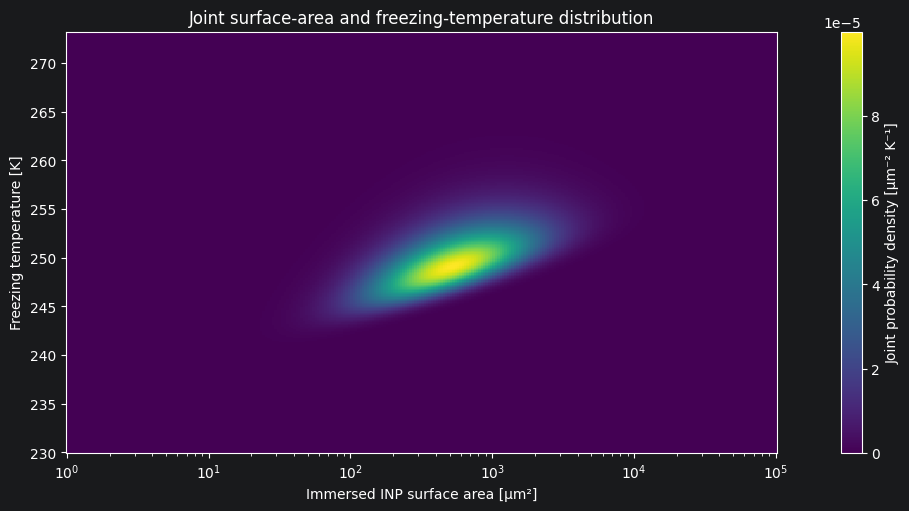

In [8]:
surface_median = formulae.trivia.sphere_surface(
    diameter=2 * 10.0*si.um
)
surface_spectrum = Lognormal(
    norm_factor=1,
    m_mode=surface_median,
    s_geom=2.55,
)
joint_pdf = pdf * surface_spectrum.pdf(A)

fig, ax = plt.subplots(figsize=(9, 5), constrained_layout=True)
plot = ax.pcolormesh(
    area / si.um**2,
    temperature / si.K,
    joint_pdf * si.um**2 * si.K,
    shading="auto",
    cmap="viridis",
)
ax.set(
    xscale="log",
    xlabel="Immersed INP surface area [µm²]",
    ylabel="Freezing temperature [K]",
    title="Joint surface-area and freezing-temperature distribution",
)
fig.colorbar(plot, ax=ax, label="Joint probability density [µm⁻² K⁻¹]")
plt.show()